In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [ ]:
model = ChatOpenAI()

In [4]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

In [5]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [6]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

In [ ]:
graph = StateGraph(BlogState)
# START--> create_outline --> create_blog --> END
# '-->': represents the flow of the state from one node to another: Edge
# create_outline and create_blog are the nodes in the graph. Each node represents a function that takes in a state and returns a new state.
# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

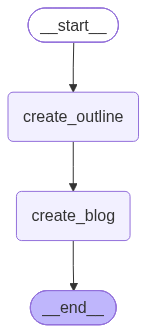

In [8]:
workflow

In [ ]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

#{'title': 'Rise of AI in India', 'outline': 'I. Introduction\n    A. Brief explanation of what AI (Artificial Intelligence) is\n    B. Overview of how AI has been steadily growing in India\n    C. Purpose of the blog - to explore the rise of AI in India and its implications\n\nII. Historical Context of AI in India\n    A. Early developments in AI in India\n    B. Government initiatives and policies to promote AI\n    C. Rise of AI startups in India\n\nIII. Current State of AI in India\n    A. Major industries leveraging AI technology in India\n    B. Indian companies leading the way in AI innovation\n    C. Impact of AI on the Indian economy and job market\n\nIV. Challenges and Opportunities\n    A. Challenges faced by AI adoption in India\n    B. Opportunities for growth and development in the AI sector\n    C. Importance of AI education and skill development in India\n\nV. Future Outlook\n    A. Predictions for the future of AI in India\n    B. Potential areas of growth and innovation in AI\n    C. Implications of AI on society and culture in India\n\nVI. Conclusion\n    A. Recap of key points discussed in the blog\n    B. Final thoughts on the rise of AI in India\n    C. Call to action for readers to stay updated on AI developments in India.', 'content': 'I. Introduction\n\nA. Artificial Intelligence (AI) is a branch of computer science that aims to create intelligent machines that can perform tasks that typically require human intelligence. These tasks can include speech recognition, decision-making, visual perception, and more. \n\nB. The field of AI has been steadily growing in India over the past few years, with advancements being made in various industries such as healthcare, finance, education, and more. \n\nC. The purpose of this blog is to explore the rise of AI in India and its implications on the economy, job market, society, and culture.\n\nII. Historical Context of AI in India\n\nA. India has a rich history in AI research, with institutions like the Indian Institute of Technology (IIT) and the Indian Statistical Institute (ISI) making significant contributions to the field. \n\nB. The Indian government has also taken steps to promote AI development in the country, with initiatives like the National AI Portal and the National Mission on Interdisciplinary Cyber-Physical Systems (NM-ICPS). \n\nC. The rise of AI startups in India has also been a key factor in driving innovation in the field, with companies like Flipkart, Zomato, and Ola using AI to improve their services.\n\nIII. Current State of AI in India\n\nA. Major industries in India are leveraging AI technology to improve efficiency, reduce costs, and enhance customer experience. Industries like healthcare, fintech, and e-commerce are leading the way in AI adoption. \n\nB. Indian companies like Wipro, Infosys, and Tata Consultancy Services (TCS) are at the forefront of AI innovation, developing cutting-edge solutions for clients both in India and globally.\n\nC. The impact of AI on the Indian economy and job market has been significant, with AI creating new job opportunities in fields like data science, machine learning, and AI development.\n\nIV. Challenges and Opportunities\n\nA. Challenges faced by AI adoption in India include issues like data privacy, security concerns, and a lack of skilled professionals in the field. \n\nB. However, there are also many opportunities for growth and development in the AI sector, with the potential to create new revenue streams, improve efficiency, and drive innovation in various industries. \n\nC. The importance of AI education and skill development in India cannot be overstated, as a trained workforce is essential for the successful implementation of AI technologies.\n\nV. Future Outlook\n\nA. Predictions for the future of AI in India include continued growth in AI adoption across industries, with AI becoming an integral part of business operations in the country. \n\nB. Potential areas of growth and innovation in AI include the development of autonomous vehicles, AI-driven healthcare solutions, and personalized customer experiences.\n\nC. The implications of AI on society and culture in India are vast, with AI technology potentially changing the way we live, work, and interact with each other.\n\nVI. Conclusion\n\nA. In conclusion, the rise of AI in India presents both challenges and opportunities for the country, with the potential to drive economic growth, create new job opportunities, and improve the lives of citizens.\n\nB. It is important for readers to stay updated on AI developments in India and to continue learning about the field to fully understand its impact on society and the economy.\n\nC. As AI continues to evolve and grow in India, it is crucial for the country to embrace this technology and leverage its potential for the benefit of all.'}

In [ ]:
print(final_state['outline'])
# I. Introduction
#     A. Brief explanation of what AI (Artificial Intelligence) is
#     B. Overview of how AI has been steadily growing in India
#     C. Purpose of the blog - to explore the rise of AI in India and its implications

# II. Historical Context of AI in India
#     A. Early developments in AI in India
#     B. Government initiatives and policies to promote AI
#     C. Rise of AI startups in India

# III. Current State of AI in India
#     A. Major industries leveraging AI technology in India
#     B. Indian companies leading the way in AI innovation
#     C. Impact of AI on the Indian economy and job market

# IV. Challenges and Opportunities
#     A. Challenges faced by AI adoption in India
#     B. Opportunities for growth and development in the AI sector
#     C. Importance of AI education and skill development in India

# V. Future Outlook
#     A. Predictions for the future of AI in India
#     B. Potential areas of growth and innovation in AI
#     C. Implications of AI on society and culture in India

# VI. Conclusion
#     A. Recap of key points discussed in the blog
#     B. Final thoughts on the rise of AI in India
#     C. Call to action for readers to stay updated on AI developments in India.

In [ ]:
print(final_state['content'])
# I. Introduction

# A. Artificial Intelligence (AI) is a branch of computer science that aims to create intelligent machines that can perform tasks that typically require human intelligence. These tasks can include speech recognition, decision-making, visual perception, and more. 

# B. The field of AI has been steadily growing in India over the past few years, with advancements being made in various industries such as healthcare, finance, education, and more. 

# C. The purpose of this blog is to explore the rise of AI in India and its implications on the economy, job market, society, and culture.

# II. Historical Context of AI in India

# A. India has a rich history in AI research, with institutions like the Indian Institute of Technology (IIT) and the Indian Statistical Institute (ISI) making significant contributions to the field. 

# B. The Indian government has also taken steps to promote AI development in the country, with initiatives like the National AI Portal and the National Mission on Interdisciplinary Cyber-Physical Systems (NM-ICPS). 

# C. The rise of AI startups in India has also been a key factor in driving innovation in the field, with companies like Flipkart, Zomato, and Ola using AI to improve their services.

# III. Current State of AI in India

# A. Major industries in India are leveraging AI technology to improve efficiency, reduce costs, and enhance customer experience. Industries like healthcare, fintech, and e-commerce are leading the way in AI adoption. 

# B. Indian companies like Wipro, Infosys, and Tata Consultancy Services (TCS) are at the forefront of AI innovation, developing cutting-edge solutions for clients both in India and globally.

# C. The impact of AI on the Indian economy and job market has been significant, with AI creating new job opportunities in fields like data science, machine learning, and AI development.

# IV. Challenges and Opportunities

# A. Challenges faced by AI adoption in India include issues like data privacy, security concerns, and a lack of skilled professionals in the field. 

# B. However, there are also many opportunities for growth and development in the AI sector, with the potential to create new revenue streams, improve efficiency, and drive innovation in various industries. 

# C. The importance of AI education and skill development in India cannot be overstated, as a trained workforce is essential for the successful implementation of AI technologies.

# V. Future Outlook

# A. Predictions for the future of AI in India include continued growth in AI adoption across industries, with AI becoming an integral part of business operations in the country. 

# B. Potential areas of growth and innovation in AI include the development of autonomous vehicles, AI-driven healthcare solutions, and personalized customer experiences.

# C. The implications of AI on society and culture in India are vast, with AI technology potentially changing the way we live, work, and interact with each other.

# VI. Conclusion

# A. In conclusion, the rise of AI in India presents both challenges and opportunities for the country, with the potential to drive economic growth, create new job opportunities, and improve the lives of citizens.

# B. It is important for readers to stay updated on AI developments in India and to continue learning about the field to fully understand its impact on society and the economy.

# C. As AI continues to evolve and grow in India, it is crucial for the country to embrace this technology and leverage its potential for the benefit of all.